# Validating the K-means Area Clusters

Goal: check that the 3 community area clusters from `05_kmeans_areas.ipynb` (issue #12) are real and lasting patterns, as Piazza Requirement 4 asks for a train/test split or cross-validation with suitable metrics.

K-means has no labels, so there is no accuracy to measure. We use two checks instead, both run on Managed Apache Spark by `src/models/kmeans_validate.py` with the same 12 features as the original model:

- **Seed stability (best of 20 restarts):** fit k = 3 on 2023–2024 with 20 different random starting points. K-means can stop in a weaker local optimum, so we keep the seed with the best silhouette score and compare every seed's grouping with it, using the adjusted Rand index (ARI: 1 = identical grouping, 0 = no better than chance).
- **Time hold-out (train/test split):** with the scaler and the best model fit on 2023–2024 trips only, put each area's 2025+ profile into the nearest cluster. We report the share of areas that stay in the same cluster, the ARI and the silhouette score of the 2025+ data under the 2023–2024 model.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.transforms import Bbox

ROOT = Path.cwd()
while not (ROOT / "data").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
RES = ROOT / "results" / "kmeans_validation"
FIGS = ROOT / "docs" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)

summary = pd.read_csv(RES / "holdout_summary.csv")
areas = pd.read_csv(RES / "holdout_areas.csv")
seeds = pd.read_csv(RES / "seed_stability.csv")
summary.round(3)

,k,best_seed,areas,same_cluster,share_same,adjusted_rand,silhouette_train,silhouette_test
0,3,1,77,77,1.0,1.0,0.646,0.64


## Time hold-out: do areas keep their cluster in 2025?

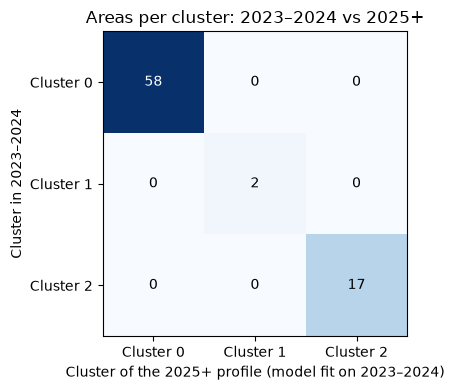

77 of 77 areas keep their cluster (100.0%), ARI 1.000, silhouette 2023-2024 0.646, 2025+ 0.640
areas that moved:


,area,name,cluster_2023_24,cluster_2025


In [2]:
table = pd.crosstab(areas["cluster_2023_24"], areas["cluster_2025"])
fig, ax = plt.subplots(figsize=(5, 4))
im = ax.imshow(table.values, cmap="Blues")
ax.set_xticks(range(len(table.columns)), [f"Cluster {c}" for c in table.columns])
ax.set_yticks(range(len(table.index)), [f"Cluster {c}" for c in table.index])
ax.set_xlabel("Cluster of the 2025+ profile (model fit on 2023–2024)")
ax.set_ylabel("Cluster in 2023–2024")
for i in range(table.shape[0]):
    for j in range(table.shape[1]):
        v = table.values[i, j]
        ax.text(j, i, v, ha="center", va="center", color="white" if v > table.values.max() / 2 else "black")
ax.set_title("Areas per cluster: 2023–2024 vs 2025+")
plt.tight_layout()
plt.savefig(FIGS / "kmeans_holdout.png", dpi=150, bbox_inches="tight")
plt.show()

s = summary.iloc[0]
print(f"{int(s.same_cluster)} of {int(s.areas)} areas keep their cluster ({100 * s.share_same:.1f}%), "
      f"ARI {s.adjusted_rand:.3f}, silhouette 2023-2024 {s.silhouette_train:.3f}, 2025+ {s.silhouette_test:.3f}")
print("areas that moved:")
areas[areas["same"] == 0][["area", "name", "cluster_2023_24", "cluster_2025"]]

All 77 areas keep their cluster when the model trained on 2023–2024 is applied to 2025+ (100%, ARI 1.000), so no area moved. The silhouette score barely changes, from 0.646 on the training years to 0.640 on 2025+, which means the old clusters separate the new data just as well. The best 2023–2024 model also gives exactly the same three groups as our M2 clusters in `05_kmeans_areas.ipynb` (17 central and lakefront areas, 58 areas in the rest of the city and the 2 airports); only the cluster numbers differ, because K-means numbers its clusters in no particular order.

## Seed stability: does the starting point change the clusters?

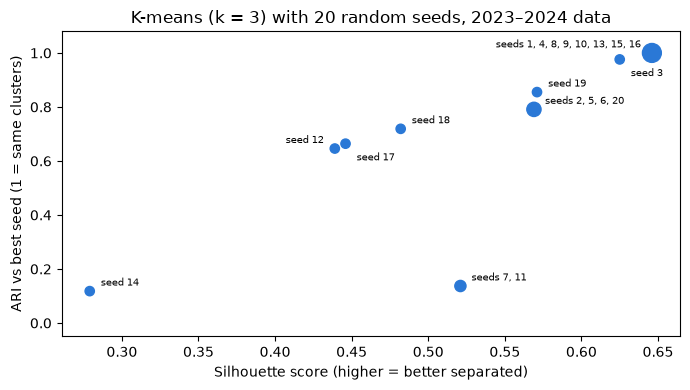

best seed: 1; 8 of 20 seeds give the same clusters (ARI > 0.99)
silhouette: mean 0.567, min 0.279, max 0.646


In [3]:
# seeds that end in the same solution share one point, labeled with all of their seed numbers
pts = (seeds.assign(sil=seeds["silhouette"].round(3), ari=seeds["adjusted_rand_vs_best"].round(3))
       .groupby(["sil", "ari"])["seed"].apply(lambda s: sorted(int(v) for v in s)).reset_index())
fig, ax = plt.subplots(figsize=(7, 4))
ax.scatter(pts["sil"], pts["ari"], s=[25 + 20 * len(s) for s in pts["seed"]], color="#2a78d6")
ax.set_ylim(-0.05, 1.08)

# place each label at the first spot that stays inside the plot and doesn't cover another label or point
fig.canvas.draw()
renderer, frame = fig.canvas.get_renderer(), ax.get_window_extent()
taken = []
for x, y in zip(pts["sil"], pts["ari"]):
    px, py = ax.transData.transform((x, y))
    taken.append(Bbox.from_extents(px - 6, py - 6, px + 6, py + 6))
for _, r in pts.sort_values("ari", ascending=False).iterrows():
    text = ("seed " if len(r.seed) == 1 else "seeds ") + ", ".join(map(str, r.seed))
    for dx, dy, ha in [(8, 4, "left"), (8, -12, "left"), (-8, 4, "right"), (-8, -12, "right"),
                       (8, 14, "left"), (-8, -22, "right"), (-8, 14, "right")]:
        label = ax.annotate(text, (r.sil, r.ari), fontsize=7, xytext=(dx, dy), textcoords="offset points", ha=ha)
        box = label.get_window_extent(renderer).expanded(1.04, 1.2)
        fits = frame.x0 <= box.x0 and box.x1 <= frame.x1 and frame.y0 <= box.y0 and box.y1 <= frame.y1
        if fits and not any(box.overlaps(t) for t in taken):
            break
        label.remove()
    else:
        label = ax.annotate(text, (r.sil, r.ari), fontsize=7, xytext=(8, 4), textcoords="offset points")
    taken.append(label.get_window_extent(renderer))
ax.set_xlabel("Silhouette score (higher = better separated)")
ax.set_ylabel("ARI vs best seed (1 = same clusters)")
ax.set_title("K-means (k = 3) with 20 random seeds, 2023–2024 data")
plt.tight_layout()
plt.savefig(FIGS / "kmeans_seed_stability.png", dpi=150, bbox_inches="tight")
plt.show()

same = (seeds["adjusted_rand_vs_best"] > 0.99).sum()
print(f"best seed: {int(summary.best_seed[0])}; {same} of {len(seeds)} seeds give the same clusters (ARI > 0.99)")
print(f"silhouette: mean {seeds.silhouette.mean():.3f}, min {seeds.silhouette.min():.3f}, max {seeds.silhouette.max():.3f}")

8 of the 20 seeds (1, 4, 8, 9, 10, 13, 15 and 16) find exactly the same clusters as the best seed, with a silhouette of 0.646, and seed 3 is almost the same (ARI 0.976). Every seed that differs has a lower silhouette, down to 0.279 for seed 14, so the differences are weaker local optima where K-means got stuck, not other good ways to group the areas. That is why we keep the best of several restarts: our first run used seed 42, which landed on a weaker solution (silhouette 0.571) that put downtown in the same cluster as the airports.

## What this means for the project

- Yes, we can trust the 3 clusters: they are the same whether K-means is fit on all 2023+ trips (M2) or only on 2023–2024, and every area stays in its cluster in 2025+, so the final report and the transit-gap discussion can use them, as long as we always keep the best of several restarts.
- The main limit is that each area is summarized by one average profile per period, so this shows the overall pattern is stable, not that every area behaves the same every month. 2025+ is also only 20 months (Jan 2025 to Aug 2026), and Spark's K-means gave different results for the same seed in our two runs (seed 7 had 0.646 in the first run and 0.521 in the second), which is one more reason to keep the best of 20.